<a href="https://colab.research.google.com/github/snkhader22/Deep-Learning-Project/blob/main/DL2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error



In [2]:
df = pd.read_csv('/content/train.csv')

In [3]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (188533, 13)

First 5 rows:


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB

Missing values:
id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0


In [4]:
# Identify numerical and categorical columns

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
['id', 'model_year', 'milage', 'price']

Categorical Columns:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [5]:
# Statistical summary of numerical columns

display(df.describe())

,id,model_year,milage,price
count,188533.000000,188533.000000,188533.000000,1.885330e+05
mean,94266.000000,2015.829998,65705.295174,4.387802e+04
std,54424.933488,5.660967,49798.158076,7.881952e+04
min,0.000000,1974.000000,100.000000,2.000000e+03
25%,47133.000000,2013.000000,24115.000000,1.700000e+04
50%,94266.000000,2017.000000,57785.000000,3.082500e+04
75%,141399.000000,2020.000000,95400.000000,4.990000e+04
max,188532.000000,2024.000000,405000.000000,2.954083e+06


Price Statistics:
count    1.885330e+05
mean     4.387802e+04
std      7.881952e+04
min      2.000000e+03
25%      1.700000e+04
50%      3.082500e+04
75%      4.990000e+04
max      2.954083e+06
Name: price, dtype: float64


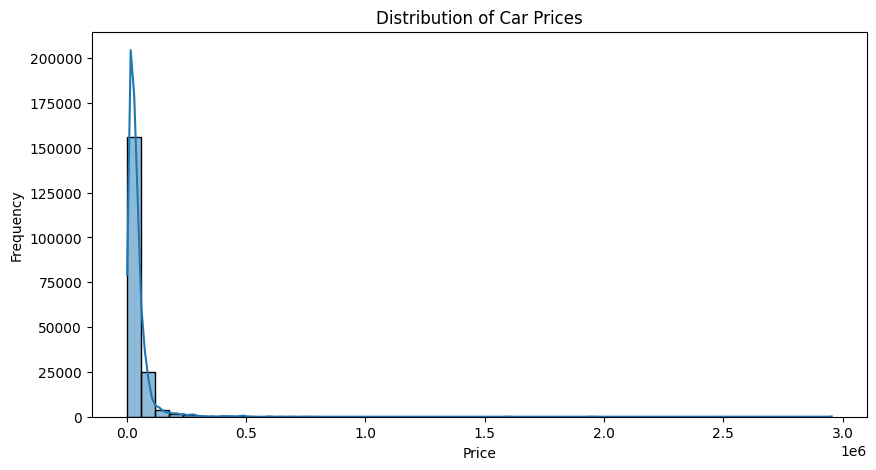

In [6]:
# Analyze target variable

print("Price Statistics:")
print(df['price'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df['price'], bins=50, kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

In [7]:
# Number of unique values in each categorical column

for col in categorical_cols:
    print(col, ":", df[col].nunique())

brand : 57
model : 1897
fuel_type : 7
engine : 1117
transmission : 52
ext_col : 319
int_col : 156
accident : 2
clean_title : 1


In [8]:
# Create a copy of the dataset
df = df.copy()

# Remove unnecessary ID column
df = df.drop(columns=['id'])

print("ID column removed successfully!")
print("New dataset shape:", df.shape)

ID column removed successfully!
New dataset shape: (188533, 12)


In [9]:
# Get categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Remove unnecessary whitespace
for col in categorical_cols:
    df[col] = df[col].str.strip()

# Convert empty strings into missing values
df[categorical_cols] = df[categorical_cols].replace(r'^\s*$', np.nan, regex=True)

print("Categorical values cleaned successfully!")

Categorical values cleaned successfully!


In [10]:
# Fill missing categorical values
for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

print("Missing categorical values handled!")

Missing categorical values handled!


In [11]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

Missing values after cleaning:
brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64

Dataset shape:
(188533, 12)

First 5 rows:


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


In [12]:
# Separate features and target

X = df.drop(columns=['price'])
y = df['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Features shape: (188533, 11)
Target shape: (188533,)

Features:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [13]:
# First split: 70% training, 30% temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation, 15% testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (131973, 11)
Validation set: (28280, 11)
Testing set: (28280, 11)


In [14]:
# Calculate dataset percentages

total = len(df)

print("Training:", round(len(X_train) / total * 100, 2), "%")
print("Validation:", round(len(X_val) / total * 100, 2), "%")
print("Testing:", round(len(X_test) / total * 100, 2), "%")

Training: 70.0 %
Validation: 15.0 %
Testing: 15.0 %


In [15]:
#Apply One-Hot Encoding

from sklearn.preprocessing import OneHotEncoder

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Categorical features:")
print(categorical_features)

# Create the encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    max_categories=50,
    sparse_output=False
)

# Fit on training data and transform all datasets
X_train_cat = encoder.fit_transform(
    X_train[categorical_features]
)

X_val_cat = encoder.transform(
    X_val[categorical_features]
)

X_test_cat = encoder.transform(
    X_test[categorical_features]
)

# Convert to float32
X_train_cat = X_train_cat.astype(np.float32)
X_val_cat = X_val_cat.astype(np.float32)
X_test_cat = X_test_cat.astype(np.float32)

print("\nEncoding completed successfully!")

print("Training categorical shape:", X_train_cat.shape)
print("Validation categorical shape:", X_val_cat.shape)
print("Testing categorical shape:", X_test_cat.shape)

print("\nTotal encoded features:", X_train_cat.shape[1])

Categorical features:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

Encoding completed successfully!
Training categorical shape: (131973, 313)
Validation categorical shape: (28280, 313)
Testing categorical shape: (28280, 313)

Total encoded features: 313


In [16]:
#Import and create the scaler

from sklearn.preprocessing import StandardScaler

# Identify numerical features
numerical_features = ['model_year', 'milage']

# Create the scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_num = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform validation and testing data
X_val_num = scaler.transform(
    X_val[numerical_features]
)

X_test_num = scaler.transform(
    X_test[numerical_features]
)

print("Numerical scaling completed!")

print("Training numerical shape:", X_train_num.shape)
print("Validation numerical shape:", X_val_num.shape)
print("Testing numerical shape:", X_test_num.shape)

Numerical scaling completed!
Training numerical shape: (131973, 2)
Validation numerical shape: (28280, 2)
Testing numerical shape: (28280, 2)


In [17]:
print("Training numerical means:")
print(X_train_num.mean(axis=0))

print("\nTraining numerical standard deviations:")
print(X_train_num.std(axis=0))

Training numerical means:
[7.73228657e-15 7.90371315e-17]

Training numerical standard deviations:
[1. 1.]


In [18]:
# Combine numerical and categorical features

X_train_final = np.concatenate(
    [X_train_num, X_train_cat], axis=1
)

X_val_final = np.concatenate(
    [X_val_num, X_val_cat], axis=1
)

X_test_final = np.concatenate(
    [X_test_num, X_test_cat], axis=1
)

print("Final feature shapes:")

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)

Final feature shapes:
Training: (131973, 315)
Validation: (28280, 315)
Testing: (28280, 315)


In [19]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create target scaler
target_scaler = StandardScaler()

# Fit on training prices only
y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

# Transform validation and testing prices
y_val_scaled = target_scaler.transform(
    y_val.to_numpy().reshape(-1, 1)
)

y_test_scaled = target_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("Target scaling completed!")
print("Training target mean:", y_train_scaled.mean())
print("Training target std:", y_train_scaled.std())

Target scaling completed!
Training target mean: 9.475841383751042e-18
Training target std: 1.0


In [20]:
# Convert features to float32
X_train_final = X_train_final.astype(np.float32)
X_val_final = X_val_final.astype(np.float32)
X_test_final = X_test_final.astype(np.float32)

# Convert features to PyTorch tensors
X_train_tensor = torch.tensor(X_train_final, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_final, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_final, dtype=torch.float32)

# Convert targets to PyTorch tensors
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

print("PyTorch tensors created successfully!")

PyTorch tensors created successfully!


In [21]:
print("Training features:", X_train_tensor.shape)
print("Training target:", y_train_tensor.shape)

print("Validation features:", X_val_tensor.shape)
print("Validation target:", y_val_tensor.shape)

print("Testing features:", X_test_tensor.shape)
print("Testing target:", y_test_tensor.shape)

Training features: torch.Size([131973, 315])
Training target: torch.Size([131973, 1])
Validation features: torch.Size([28280, 315])
Validation target: torch.Size([28280, 1])
Testing features: torch.Size([28280, 315])
Testing target: torch.Size([28280, 1])


In [22]:
# Define Linear Regression model

class LinearRegressionModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.linear = nn.Linear(input_size, 1)

    def forward(self, x):
        return self.linear(x)


# Create the model
linear_model = LinearRegressionModel(input_size=315)

print(linear_model)

LinearRegressionModel(
  (linear): Linear(in_features=315, out_features=1, bias=True)
)


In [23]:
from torch.utils.data import TensorDataset, DataLoader

# Create training dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
optimizer = optim.Adam(
    linear_model.parameters(),
    lr=0.01
)

# Number of epochs
epochs = 30

print("Training setup completed!")

Training setup completed!


In [24]:
# Store training and validation losses
linear_train_losses = []
linear_val_losses = []

for epoch in range(epochs):

    # Training mode
    linear_model.train()

    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        # Forward pass
        predictions = linear_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation mode
    linear_model.eval()

    with torch.no_grad():

        val_predictions = linear_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    linear_train_losses.append(train_loss)
    linear_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Linear Regression training completed!")

Epoch [1/30], Train Loss: 0.8934, Val Loss: 0.7044
Epoch [2/30], Train Loss: 0.8887, Val Loss: 0.7078
Epoch [3/30], Train Loss: 0.8881, Val Loss: 0.7050
Epoch [4/30], Train Loss: 0.8887, Val Loss: 0.7067
Epoch [5/30], Train Loss: 0.8880, Val Loss: 0.7075
Epoch [6/30], Train Loss: 0.8883, Val Loss: 0.7079
Epoch [7/30], Train Loss: 0.8890, Val Loss: 0.7058
Epoch [8/30], Train Loss: 0.8879, Val Loss: 0.7078
Epoch [9/30], Train Loss: 0.8888, Val Loss: 0.7063
Epoch [10/30], Train Loss: 0.8887, Val Loss: 0.7033
Epoch [11/30], Train Loss: 0.8879, Val Loss: 0.7079
Epoch [12/30], Train Loss: 0.8885, Val Loss: 0.7078
Epoch [13/30], Train Loss: 0.8884, Val Loss: 0.7062
Epoch [14/30], Train Loss: 0.8880, Val Loss: 0.7066
Epoch [15/30], Train Loss: 0.8889, Val Loss: 0.7049
Epoch [16/30], Train Loss: 0.8890, Val Loss: 0.7050
Epoch [17/30], Train Loss: 0.8880, Val Loss: 0.7078
Epoch [18/30], Train Loss: 0.8887, Val Loss: 0.7051
Epoch [19/30], Train Loss: 0.8882, Val Loss: 0.7034
Epoch [20/30], Train 

In [25]:
# Convert predictions back to original price scale

linear_model.eval()

with torch.no_grad():

    train_pred_scaled = linear_model(X_train_tensor).numpy()
    val_pred_scaled = linear_model(X_val_tensor).numpy()

    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
linear_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

linear_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Linear Regression Results")
print("--------------------------")
print("Training MSE:", linear_train_mse)
print("Validation MSE:", linear_val_mse)

Linear Regression Results
--------------------------
Training MSE: 5848595968.0
Validation MSE: 4673319424.0


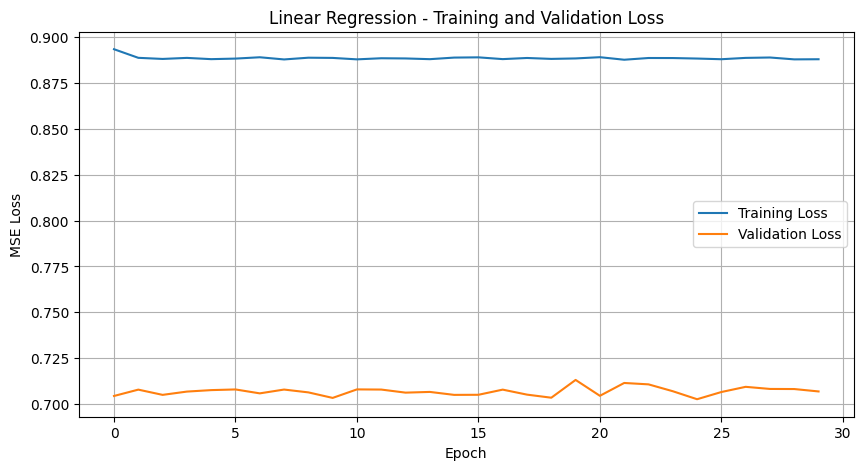

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    linear_train_losses,
    label="Training Loss"
)

plt.plot(
    linear_val_losses,
    label="Validation Loss"
)

plt.title("Linear Regression - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

In [27]:
# Define Deep Neural Network

class DeepNeuralNetwork(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
dnn_model = DeepNeuralNetwork(input_size=315)

print(dnn_model)

DeepNeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [28]:
# Create DataLoader for DNN

dnn_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
dnn_optimizer = optim.Adam(
    dnn_model.parameters(),
    lr=0.001
)

# Number of epochs
epochs = 30

print("DNN training setup completed!")

DNN training setup completed!


In [29]:
# Store training and validation losses

dnn_train_losses = []
dnn_val_losses = []

for epoch in range(epochs):

    dnn_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = dnn_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        dnn_optimizer.zero_grad()

        loss.backward()

        dnn_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    dnn_model.eval()

    with torch.no_grad():

        val_predictions = dnn_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    dnn_train_losses.append(train_loss)
    dnn_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("DNN training completed!")

Epoch [1/30], Train Loss: 0.8819, Val Loss: 0.6871
Epoch [2/30], Train Loss: 0.8668, Val Loss: 0.6917
Epoch [3/30], Train Loss: 0.8616, Val Loss: 0.7030
Epoch [4/30], Train Loss: 0.8581, Val Loss: 0.6962
Epoch [5/30], Train Loss: 0.8537, Val Loss: 0.6863
Epoch [6/30], Train Loss: 0.8483, Val Loss: 0.6885
Epoch [7/30], Train Loss: 0.8436, Val Loss: 0.6925
Epoch [8/30], Train Loss: 0.8356, Val Loss: 0.6902
Epoch [9/30], Train Loss: 0.8250, Val Loss: 0.6943
Epoch [10/30], Train Loss: 0.8148, Val Loss: 0.6904
Epoch [11/30], Train Loss: 0.7953, Val Loss: 0.7242
Epoch [12/30], Train Loss: 0.7692, Val Loss: 0.7156
Epoch [13/30], Train Loss: 0.7543, Val Loss: 0.7356
Epoch [14/30], Train Loss: 0.7273, Val Loss: 0.7041
Epoch [15/30], Train Loss: 0.7086, Val Loss: 0.7609
Epoch [16/30], Train Loss: 0.6885, Val Loss: 0.7110
Epoch [17/30], Train Loss: 0.6764, Val Loss: 0.7235
Epoch [18/30], Train Loss: 0.6606, Val Loss: 0.7727
Epoch [19/30], Train Loss: 0.6536, Val Loss: 0.7926
Epoch [20/30], Train 

In [30]:
# Evaluate DNN

dnn_model.eval()

with torch.no_grad():

    train_pred_scaled = dnn_model(X_train_tensor).numpy()

    val_pred_scaled = dnn_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
dnn_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

dnn_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Deep Neural Network Results")
print("---------------------------")

print("Training MSE:", dnn_train_mse)

print("Validation MSE:", dnn_val_mse)

Deep Neural Network Results
---------------------------
Training MSE: 3696523008.0
Validation MSE: 5014794752.0


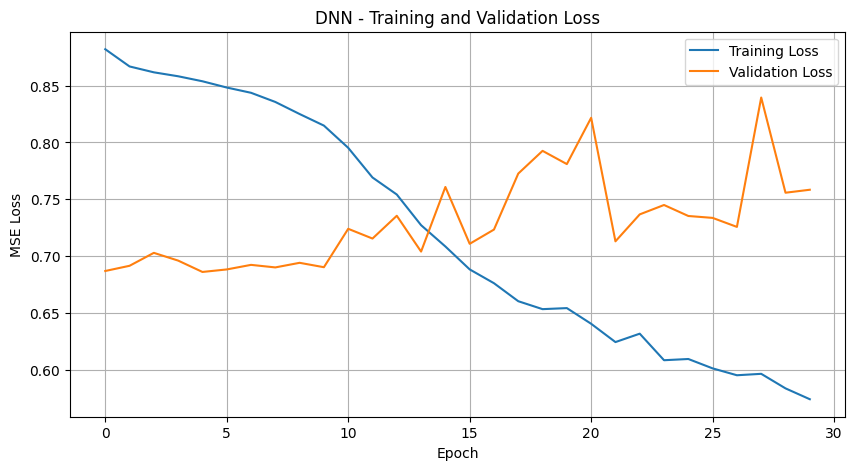

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(
    dnn_train_losses,
    label="Training Loss"
)

plt.plot(
    dnn_val_losses,
    label="Validation Loss"
)

plt.title("DNN - Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [32]:
# Compare baseline models

comparison = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Deep Neural Network"
    ],

    "Training MSE": [
        linear_train_mse,
        dnn_train_mse
    ],

    "Validation MSE": [
        linear_val_mse,
        dnn_val_mse
    ]

})

display(comparison)

,Model,Training MSE,Validation MSE
0,Linear Regression,5.848596e+09,4.673319e+09
1,Deep Neural Network,3.696523e+09,5.014795e+09


In [69]:
# EXPERIMENT 1 - LEARNING RATE 0.00001

# Create a fresh DNN model
exp1_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.00001
exp1_optimizer = optim.Adam(
    exp1_model.parameters(),
    lr=0.00001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp1_train_losses = []
exp1_val_losses = []

print("Experiment 1 setup completed!")

Experiment 1 setup completed!


In [70]:
# EXPERIMENT 1 - TRAIN MODEL

for epoch in range(30):

    # Set model to training mode
    exp1_model.train()

    total_train_loss = 0

    # Loop through training batches
    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp1_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp1_optimizer.zero_grad()

        loss.backward()

        exp1_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp1_model.eval()

    with torch.no_grad():

        val_predictions = exp1_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp1_train_losses.append(train_loss)
    exp1_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 1 completed!")

Epoch [1/30], Train Loss: 1.0113, Val Loss: 0.8165
Epoch [2/30], Train Loss: 0.9869, Val Loss: 0.7876
Epoch [3/30], Train Loss: 0.9526, Val Loss: 0.7497
Epoch [4/30], Train Loss: 0.9211, Val Loss: 0.7258
Epoch [5/30], Train Loss: 0.9054, Val Loss: 0.7163
Epoch [6/30], Train Loss: 0.8985, Val Loss: 0.7112
Epoch [7/30], Train Loss: 0.8938, Val Loss: 0.7073
Epoch [8/30], Train Loss: 0.8900, Val Loss: 0.7041
Epoch [9/30], Train Loss: 0.8869, Val Loss: 0.7014
Epoch [10/30], Train Loss: 0.8842, Val Loss: 0.6992
Epoch [11/30], Train Loss: 0.8819, Val Loss: 0.6973
Epoch [12/30], Train Loss: 0.8799, Val Loss: 0.6956
Epoch [13/30], Train Loss: 0.8780, Val Loss: 0.6941
Epoch [14/30], Train Loss: 0.8764, Val Loss: 0.6927
Epoch [15/30], Train Loss: 0.8749, Val Loss: 0.6915
Epoch [16/30], Train Loss: 0.8736, Val Loss: 0.6906
Epoch [17/30], Train Loss: 0.8724, Val Loss: 0.6897
Epoch [18/30], Train Loss: 0.8714, Val Loss: 0.6888
Epoch [19/30], Train Loss: 0.8705, Val Loss: 0.6881
Epoch [20/30], Train 

In [71]:
# EXPERIMENT 1 - EVALUATE MODEL

exp1_model.eval()

with torch.no_grad():

    exp1_val_scaled = exp1_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp1_val_predictions = target_scaler.inverse_transform(
        exp1_val_scaled
    )

# Calculate validation MSE
exp1_val_mse = mean_squared_error(
    y_val,
    exp1_val_predictions
)

print("Experiment 1 Validation MSE:", exp1_val_mse)

Experiment 1 Validation MSE: 4519318016.0


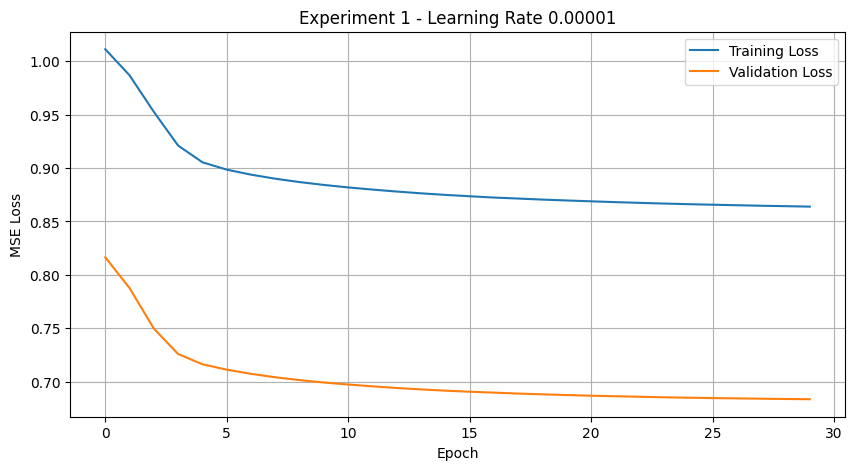

In [72]:
# EXPERIMENT 1 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp1_train_losses,
    label="Training Loss"
)

plt.plot(
    exp1_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 1 - Learning Rate 0.00001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [73]:
# EXPERIMENT 2 - LEARNING RATE 0.0001

# Create a fresh DNN model
exp2_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.0001
exp2_optimizer = optim.Adam(
    exp2_model.parameters(),
    lr=0.0001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp2_train_losses = []
exp2_val_losses = []

print("Experiment 2 setup completed!")

Experiment 2 setup completed!


In [74]:
# EXPERIMENT 2 - TRAIN MODEL

for epoch in range(30):

    exp2_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp2_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp2_optimizer.zero_grad()

        loss.backward()

        exp2_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp2_model.eval()

    with torch.no_grad():

        val_predictions = exp2_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp2_train_losses.append(train_loss)
    exp2_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 2 completed!")

Epoch [1/30], Train Loss: 0.9269, Val Loss: 0.7009
Epoch [2/30], Train Loss: 0.8770, Val Loss: 0.6874
Epoch [3/30], Train Loss: 0.8688, Val Loss: 0.6860
Epoch [4/30], Train Loss: 0.8653, Val Loss: 0.6831
Epoch [5/30], Train Loss: 0.8627, Val Loss: 0.6828
Epoch [6/30], Train Loss: 0.8609, Val Loss: 0.6829
Epoch [7/30], Train Loss: 0.8591, Val Loss: 0.6826
Epoch [8/30], Train Loss: 0.8577, Val Loss: 0.6835
Epoch [9/30], Train Loss: 0.8560, Val Loss: 0.6827
Epoch [10/30], Train Loss: 0.8544, Val Loss: 0.6828
Epoch [11/30], Train Loss: 0.8529, Val Loss: 0.6838
Epoch [12/30], Train Loss: 0.8511, Val Loss: 0.6834
Epoch [13/30], Train Loss: 0.8495, Val Loss: 0.6838
Epoch [14/30], Train Loss: 0.8480, Val Loss: 0.6843
Epoch [15/30], Train Loss: 0.8460, Val Loss: 0.6847
Epoch [16/30], Train Loss: 0.8436, Val Loss: 0.6846
Epoch [17/30], Train Loss: 0.8418, Val Loss: 0.6845
Epoch [18/30], Train Loss: 0.8399, Val Loss: 0.6861
Epoch [19/30], Train Loss: 0.8372, Val Loss: 0.6877
Epoch [20/30], Train 

In [75]:
# EXPERIMENT 2 - EVALUATE MODEL

exp2_model.eval()

with torch.no_grad():

    exp2_val_scaled = exp2_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp2_val_predictions = target_scaler.inverse_transform(
        exp2_val_scaled
    )

# Calculate validation MSE
exp2_val_mse = mean_squared_error(
    y_val,
    exp2_val_predictions
)

print("Experiment 2 Validation MSE:", exp2_val_mse)

Experiment 2 Validation MSE: 4644907520.0


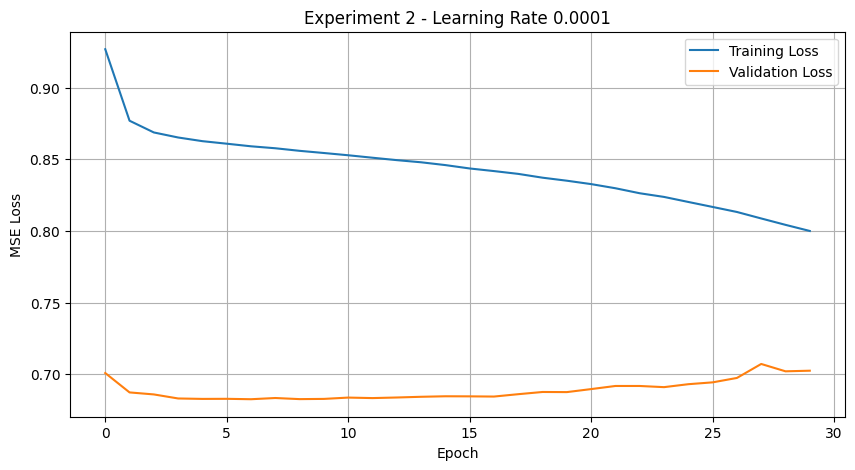

In [76]:
# EXPERIMENT 2 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp2_train_losses,
    label="Training Loss"
)

plt.plot(
    exp2_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 2 - Learning Rate 0.0001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [77]:
# EXPERIMENT 3 - LEARNING RATE 0.0005

# Create a fresh DNN model
exp3_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.0005
exp3_optimizer = optim.Adam(
    exp3_model.parameters(),
    lr=0.0005
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp3_train_losses = []
exp3_val_losses = []

print("Experiment 3 setup completed!")

Experiment 3 setup completed!


In [78]:
# EXPERIMENT 3 - TRAIN MODEL

for epoch in range(30):

    exp3_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp3_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp3_optimizer.zero_grad()

        loss.backward()

        exp3_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp3_model.eval()

    with torch.no_grad():

        val_predictions = exp3_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp3_train_losses.append(train_loss)
    exp3_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 3 completed!")

Epoch [1/30], Train Loss: 0.8852, Val Loss: 0.6844
Epoch [2/30], Train Loss: 0.8659, Val Loss: 0.6829
Epoch [3/30], Train Loss: 0.8620, Val Loss: 0.6849
Epoch [4/30], Train Loss: 0.8589, Val Loss: 0.6854
Epoch [5/30], Train Loss: 0.8563, Val Loss: 0.6833
Epoch [6/30], Train Loss: 0.8529, Val Loss: 0.6858
Epoch [7/30], Train Loss: 0.8501, Val Loss: 0.6866
Epoch [8/30], Train Loss: 0.8463, Val Loss: 0.6886
Epoch [9/30], Train Loss: 0.8413, Val Loss: 0.6874
Epoch [10/30], Train Loss: 0.8349, Val Loss: 0.6967
Epoch [11/30], Train Loss: 0.8258, Val Loss: 0.6950
Epoch [12/30], Train Loss: 0.8171, Val Loss: 0.7010
Epoch [13/30], Train Loss: 0.8059, Val Loss: 0.6952
Epoch [14/30], Train Loss: 0.7896, Val Loss: 0.7421
Epoch [15/30], Train Loss: 0.7756, Val Loss: 0.7101
Epoch [16/30], Train Loss: 0.7571, Val Loss: 0.7153
Epoch [17/30], Train Loss: 0.7375, Val Loss: 0.7177
Epoch [18/30], Train Loss: 0.7182, Val Loss: 0.7792
Epoch [19/30], Train Loss: 0.7085, Val Loss: 0.7125
Epoch [20/30], Train 

In [79]:
# EXPERIMENT 3 - EVALUATE MODEL

exp3_model.eval()

with torch.no_grad():

    exp3_val_scaled = exp3_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp3_val_predictions = target_scaler.inverse_transform(
        exp3_val_scaled
    )

# Calculate validation MSE
exp3_val_mse = mean_squared_error(
    y_val,
    exp3_val_predictions
)

print("Experiment 3 Validation MSE:", exp3_val_mse)

Experiment 3 Validation MSE: 5526369792.0


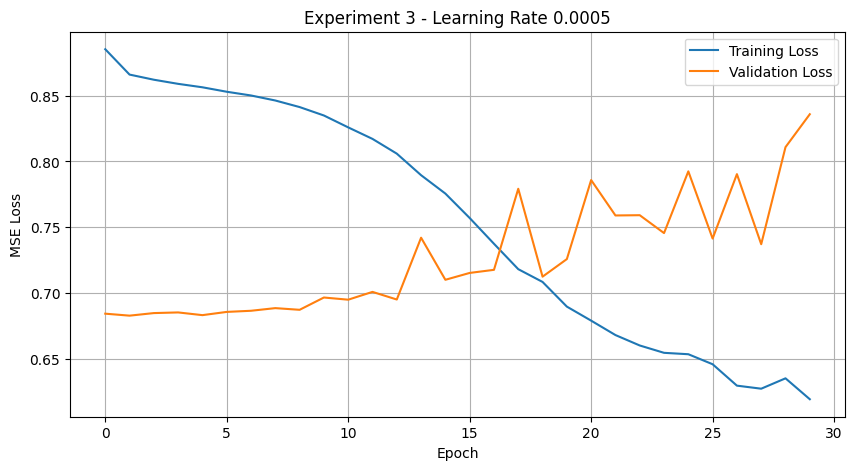

In [80]:
# EXPERIMENT 3 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp3_train_losses,
    label="Training Loss"
)

plt.plot(
    exp3_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 3 - Learning Rate 0.0005")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [81]:
# EXPERIMENT 4 - LEARNING RATE 0.001

# Create a fresh DNN model
exp4_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.001
exp4_optimizer = optim.Adam(
    exp4_model.parameters(),
    lr=0.001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp4_train_losses = []
exp4_val_losses = []

print("Experiment 4 setup completed!")

Experiment 4 setup completed!


In [82]:
# EXPERIMENT 4 - TRAIN MODEL

for epoch in range(30):

    exp4_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp4_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp4_optimizer.zero_grad()

        loss.backward()

        exp4_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp4_model.eval()

    with torch.no_grad():

        val_predictions = exp4_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp4_train_losses.append(train_loss)
    exp4_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 4 completed!")

Epoch [1/30], Train Loss: 0.8797, Val Loss: 0.6863
Epoch [2/30], Train Loss: 0.8658, Val Loss: 0.6831
Epoch [3/30], Train Loss: 0.8608, Val Loss: 0.6842
Epoch [4/30], Train Loss: 0.8580, Val Loss: 0.6881
Epoch [5/30], Train Loss: 0.8539, Val Loss: 0.6866
Epoch [6/30], Train Loss: 0.8497, Val Loss: 0.6841
Epoch [7/30], Train Loss: 0.8444, Val Loss: 0.7005
Epoch [8/30], Train Loss: 0.8378, Val Loss: 0.6921
Epoch [9/30], Train Loss: 0.8282, Val Loss: 0.6950
Epoch [10/30], Train Loss: 0.8161, Val Loss: 0.7034
Epoch [11/30], Train Loss: 0.8008, Val Loss: 0.7003
Epoch [12/30], Train Loss: 0.7829, Val Loss: 0.7306
Epoch [13/30], Train Loss: 0.7543, Val Loss: 0.7079
Epoch [14/30], Train Loss: 0.7349, Val Loss: 0.6913
Epoch [15/30], Train Loss: 0.7200, Val Loss: 0.7170
Epoch [16/30], Train Loss: 0.7090, Val Loss: 0.7309
Epoch [17/30], Train Loss: 0.6782, Val Loss: 0.7814
Epoch [18/30], Train Loss: 0.6710, Val Loss: 0.7246
Epoch [19/30], Train Loss: 0.6597, Val Loss: 0.7795
Epoch [20/30], Train 

In [83]:
# EXPERIMENT 4 - EVALUATE MODEL

exp4_model.eval()

with torch.no_grad():

    exp4_val_scaled = exp4_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp4_val_predictions = target_scaler.inverse_transform(
        exp4_val_scaled
    )

# Calculate validation MSE
exp4_val_mse = mean_squared_error(
    y_val,
    exp4_val_predictions
)

print("Experiment 4 Validation MSE:", exp4_val_mse)

Experiment 4 Validation MSE: 5642189824.0


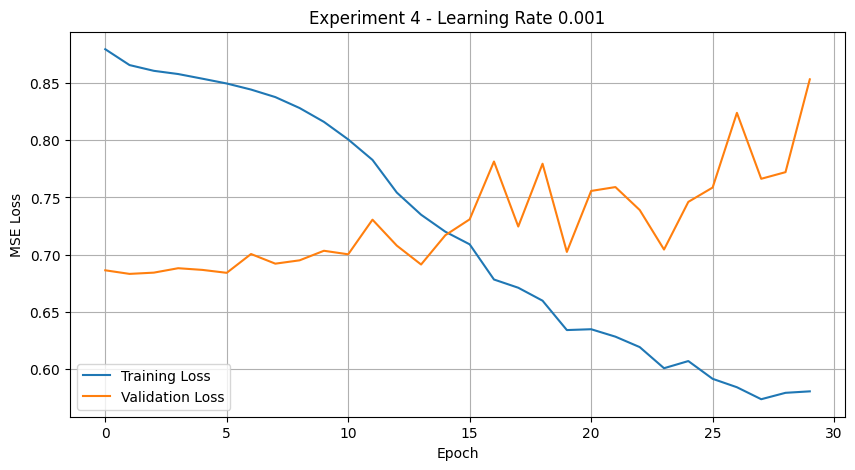

In [84]:
# EXPERIMENT 4 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp4_train_losses,
    label="Training Loss"
)

plt.plot(
    exp4_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 4 - Learning Rate 0.001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [85]:
# EXPERIMENT 5 - LEARNING RATE 0.01

# Create a fresh DNN model
exp5_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.01
exp5_optimizer = optim.Adam(
    exp5_model.parameters(),
    lr=0.01
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp5_train_losses = []
exp5_val_losses = []

print("Experiment 5 setup completed!")

Experiment 5 setup completed!


In [86]:
# EXPERIMENT 5 - TRAIN MODEL

for epoch in range(30):

    exp5_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp5_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp5_optimizer.zero_grad()

        loss.backward()

        exp5_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp5_model.eval()

    with torch.no_grad():

        val_predictions = exp5_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp5_train_losses.append(train_loss)
    exp5_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 5 completed!")

Epoch [1/30], Train Loss: 0.8832, Val Loss: 0.6944
Epoch [2/30], Train Loss: 0.8732, Val Loss: 0.6874
Epoch [3/30], Train Loss: 0.8687, Val Loss: 0.6927
Epoch [4/30], Train Loss: 0.8658, Val Loss: 0.6846
Epoch [5/30], Train Loss: 0.8620, Val Loss: 0.6960
Epoch [6/30], Train Loss: 0.8563, Val Loss: 0.6905
Epoch [7/30], Train Loss: 0.8545, Val Loss: 0.6956
Epoch [8/30], Train Loss: 0.8477, Val Loss: 0.6960
Epoch [9/30], Train Loss: 0.8371, Val Loss: 0.6989
Epoch [10/30], Train Loss: 0.8453, Val Loss: 0.6916
Epoch [11/30], Train Loss: 0.8372, Val Loss: 0.7018
Epoch [12/30], Train Loss: 0.8311, Val Loss: 0.7086
Epoch [13/30], Train Loss: 0.8323, Val Loss: 0.7003
Epoch [14/30], Train Loss: 0.8235, Val Loss: 0.8006
Epoch [15/30], Train Loss: 0.8222, Val Loss: 0.6962
Epoch [16/30], Train Loss: 0.8205, Val Loss: 0.7975
Epoch [17/30], Train Loss: 0.7934, Val Loss: 0.7076
Epoch [18/30], Train Loss: 0.7849, Val Loss: 0.7082
Epoch [19/30], Train Loss: 0.7994, Val Loss: 0.7086
Epoch [20/30], Train 

In [87]:
# EXPERIMENT 5 - EVALUATE MODEL

exp5_model.eval()

with torch.no_grad():

    exp5_val_scaled = exp5_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp5_val_predictions = target_scaler.inverse_transform(
        exp5_val_scaled
    )

# Calculate validation MSE
exp5_val_mse = mean_squared_error(
    y_val,
    exp5_val_predictions
)

print("Experiment 5 Validation MSE:", exp5_val_mse)

Experiment 5 Validation MSE: 5009022976.0


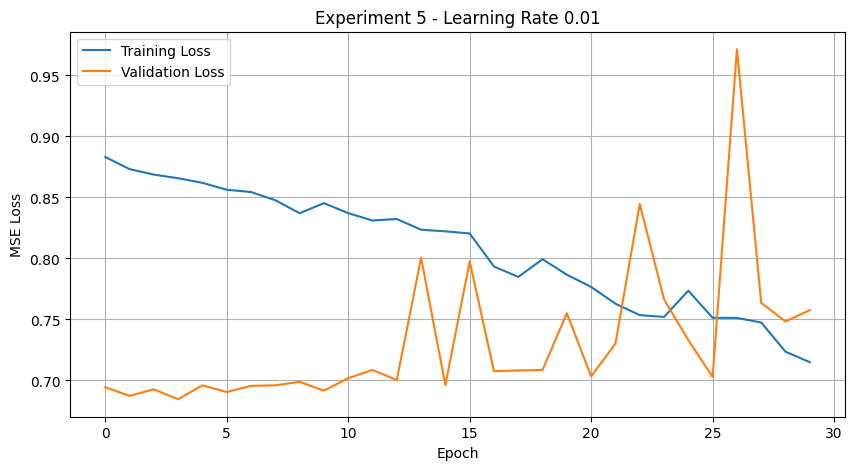

In [88]:
# EXPERIMENT 5 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp5_train_losses,
    label="Training Loss"
)

plt.plot(
    exp5_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 5 - Learning Rate 0.01")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [89]:
# EXPERIMENT 6 - LEARNING RATE 0.1

# Create a fresh DNN model
exp6_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.1
exp6_optimizer = optim.Adam(
    exp6_model.parameters(),
    lr=0.1
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp6_train_losses = []
exp6_val_losses = []

print("Experiment 6 setup completed!")

Experiment 6 setup completed!


In [90]:
# EXPERIMENT 6 - TRAIN MODEL

for epoch in range(30):

    exp6_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp6_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp6_optimizer.zero_grad()

        loss.backward()

        exp6_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp6_model.eval()

    with torch.no_grad():

        val_predictions = exp6_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp6_train_losses.append(train_loss)
    exp6_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 6 completed!")

Epoch [1/30], Train Loss: 1.6348, Val Loss: 0.8502
Epoch [2/30], Train Loss: 0.9289, Val Loss: 0.7110
Epoch [3/30], Train Loss: 0.9005, Val Loss: 0.7064
Epoch [4/30], Train Loss: 0.8894, Val Loss: 0.6991
Epoch [5/30], Train Loss: 0.8874, Val Loss: 0.7025
Epoch [6/30], Train Loss: 0.8900, Val Loss: 0.7057
Epoch [7/30], Train Loss: 0.8912, Val Loss: 0.7297
Epoch [8/30], Train Loss: 0.8929, Val Loss: 0.7262
Epoch [9/30], Train Loss: 0.9003, Val Loss: 0.7148
Epoch [10/30], Train Loss: 0.9018, Val Loss: 0.7852
Epoch [11/30], Train Loss: 0.8989, Val Loss: 0.7161
Epoch [12/30], Train Loss: 0.8974, Val Loss: 0.8609
Epoch [13/30], Train Loss: 0.8996, Val Loss: 0.7021
Epoch [14/30], Train Loss: 0.8904, Val Loss: 0.6998
Epoch [15/30], Train Loss: 0.8884, Val Loss: 0.7097
Epoch [16/30], Train Loss: 0.8910, Val Loss: 0.7136
Epoch [17/30], Train Loss: 0.8928, Val Loss: 0.7192
Epoch [18/30], Train Loss: 0.8914, Val Loss: 0.7080
Epoch [19/30], Train Loss: 0.8878, Val Loss: 0.7084
Epoch [20/30], Train 

In [91]:
# EXPERIMENT 6 - EVALUATE MODEL

exp6_model.eval()

with torch.no_grad():

    exp6_val_scaled = exp6_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp6_val_predictions = target_scaler.inverse_transform(
        exp6_val_scaled
    )

# Calculate validation MSE
exp6_val_mse = mean_squared_error(
    y_val,
    exp6_val_predictions
)

print("Experiment 6 Validation MSE:", exp6_val_mse)

Experiment 6 Validation MSE: 4715601408.0


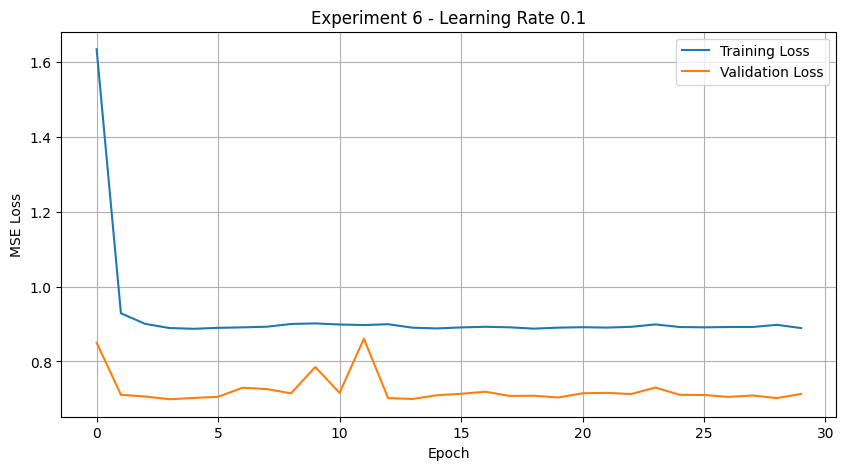

In [92]:
# EXPERIMENT 6 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp6_train_losses,
    label="Training Loss"
)

plt.plot(
    exp6_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 6 - Learning Rate 0.1")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [93]:
# EXPERIMENT 7 - ADAM OPTIMIZER

# Create a fresh DNN model
exp7_model = DeepNeuralNetwork(input_size=315)

# Define Adam optimizer
exp7_optimizer = optim.Adam(
    exp7_model.parameters(),
    lr=0.00001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp7_train_losses = []
exp7_val_losses = []

print("Experiment 7 setup completed!")

Experiment 7 setup completed!


In [94]:
# EXPERIMENT 7 - TRAIN MODEL

for epoch in range(30):

    exp7_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp7_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp7_optimizer.zero_grad()

        loss.backward()

        exp7_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp7_model.eval()

    with torch.no_grad():

        val_predictions = exp7_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp7_train_losses.append(train_loss)
    exp7_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 7 completed!")

Epoch [1/30], Train Loss: 0.9980, Val Loss: 0.8078
Epoch [2/30], Train Loss: 0.9794, Val Loss: 0.7802
Epoch [3/30], Train Loss: 0.9469, Val Loss: 0.7455
Epoch [4/30], Train Loss: 0.9200, Val Loss: 0.7267
Epoch [5/30], Train Loss: 0.9075, Val Loss: 0.7182
Epoch [6/30], Train Loss: 0.9006, Val Loss: 0.7127
Epoch [7/30], Train Loss: 0.8956, Val Loss: 0.7087
Epoch [8/30], Train Loss: 0.8916, Val Loss: 0.7054
Epoch [9/30], Train Loss: 0.8883, Val Loss: 0.7027
Epoch [10/30], Train Loss: 0.8856, Val Loss: 0.7004
Epoch [11/30], Train Loss: 0.8832, Val Loss: 0.6984
Epoch [12/30], Train Loss: 0.8811, Val Loss: 0.6967
Epoch [13/30], Train Loss: 0.8793, Val Loss: 0.6952
Epoch [14/30], Train Loss: 0.8777, Val Loss: 0.6939
Epoch [15/30], Train Loss: 0.8762, Val Loss: 0.6927
Epoch [16/30], Train Loss: 0.8749, Val Loss: 0.6918
Epoch [17/30], Train Loss: 0.8737, Val Loss: 0.6908
Epoch [18/30], Train Loss: 0.8726, Val Loss: 0.6899
Epoch [19/30], Train Loss: 0.8717, Val Loss: 0.6891
Epoch [20/30], Train 

In [95]:
# EXPERIMENT 7 - EVALUATE MODEL

exp7_model.eval()

with torch.no_grad():

    exp7_val_scaled = exp7_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp7_val_predictions = target_scaler.inverse_transform(
        exp7_val_scaled
    )

# Calculate validation MSE
exp7_val_mse = mean_squared_error(
    y_val,
    exp7_val_predictions
)

print("Experiment 7 Validation MSE:", exp7_val_mse)

Experiment 7 Validation MSE: 4524460032.0


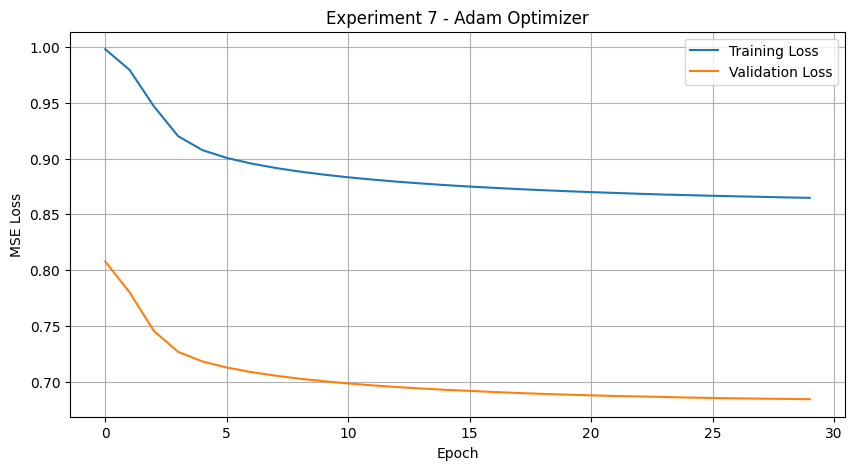

In [96]:
# EXPERIMENT 7 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp7_train_losses,
    label="Training Loss"
)

plt.plot(
    exp7_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 7 - Adam Optimizer")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [97]:
# EXPERIMENT 8 - SGD OPTIMIZER

# Create a fresh DNN model
exp8_model = DeepNeuralNetwork(input_size=315)

# Define SGD optimizer
exp8_optimizer = optim.SGD(
    exp8_model.parameters(),
    lr=0.00001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp8_train_losses = []
exp8_val_losses = []

print("Experiment 8 setup completed!")

Experiment 8 setup completed!


In [98]:
# EXPERIMENT 8 - TRAIN MODEL

for epoch in range(30):

    exp8_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp8_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp8_optimizer.zero_grad()

        loss.backward()

        exp8_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp8_model.eval()

    with torch.no_grad():

        val_predictions = exp8_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp8_train_losses.append(train_loss)
    exp8_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 8 completed!")

Epoch [1/30], Train Loss: 1.0184, Val Loss: 0.8344
Epoch [2/30], Train Loss: 1.0178, Val Loss: 0.8338
Epoch [3/30], Train Loss: 1.0173, Val Loss: 0.8333
Epoch [4/30], Train Loss: 1.0168, Val Loss: 0.8328
Epoch [5/30], Train Loss: 1.0163, Val Loss: 0.8323
Epoch [6/30], Train Loss: 1.0158, Val Loss: 0.8319
Epoch [7/30], Train Loss: 1.0153, Val Loss: 0.8314
Epoch [8/30], Train Loss: 1.0149, Val Loss: 0.8309
Epoch [9/30], Train Loss: 1.0144, Val Loss: 0.8305
Epoch [10/30], Train Loss: 1.0140, Val Loss: 0.8301
Epoch [11/30], Train Loss: 1.0136, Val Loss: 0.8297
Epoch [12/30], Train Loss: 1.0132, Val Loss: 0.8293
Epoch [13/30], Train Loss: 1.0128, Val Loss: 0.8289
Epoch [14/30], Train Loss: 1.0124, Val Loss: 0.8285
Epoch [15/30], Train Loss: 1.0120, Val Loss: 0.8281
Epoch [16/30], Train Loss: 1.0116, Val Loss: 0.8278
Epoch [17/30], Train Loss: 1.0113, Val Loss: 0.8274
Epoch [18/30], Train Loss: 1.0109, Val Loss: 0.8271
Epoch [19/30], Train Loss: 1.0106, Val Loss: 0.8267
Epoch [20/30], Train 

In [99]:
# EXPERIMENT 8 - EVALUATE MODEL

exp8_model.eval()

with torch.no_grad():

    exp8_val_scaled = exp8_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp8_val_predictions = target_scaler.inverse_transform(
        exp8_val_scaled
    )

# Calculate validation MSE
exp8_val_mse = mean_squared_error(
    y_val,
    exp8_val_predictions
)

print("Experiment 8 Validation MSE:", exp8_val_mse)

Experiment 8 Validation MSE: 5445747712.0


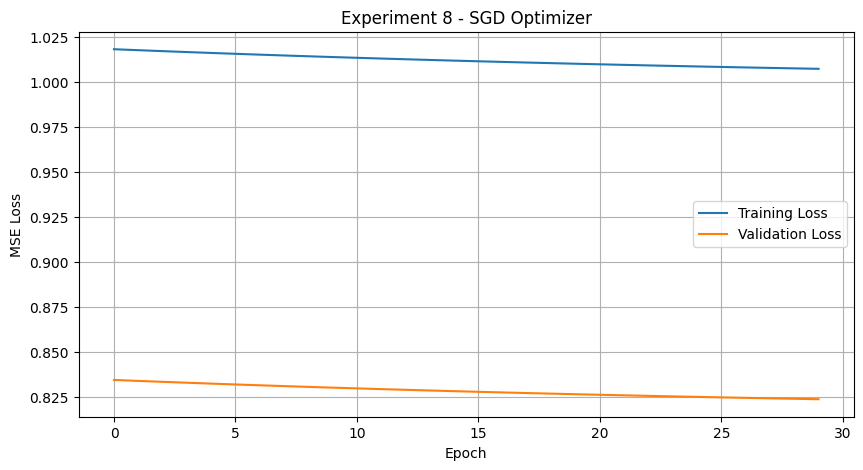

In [100]:
# EXPERIMENT 8 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp8_train_losses,
    label="Training Loss"
)

plt.plot(
    exp8_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 8 - SGD Optimizer")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [101]:
# EXPERIMENT 9 - SGD WITH MOMENTUM

# Create a fresh DNN model
exp9_model = DeepNeuralNetwork(input_size=315)

# Define SGD optimizer with Momentum
exp9_optimizer = optim.SGD(
    exp9_model.parameters(),
    lr=0.00001,
    momentum=0.9
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp9_train_losses = []
exp9_val_losses = []

print("Experiment 9 setup completed!")

Experiment 9 setup completed!


In [102]:
# EXPERIMENT 9 - TRAIN MODEL

for epoch in range(30):

    exp9_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp9_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp9_optimizer.zero_grad()

        loss.backward()

        exp9_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp9_model.eval()

    with torch.no_grad():

        val_predictions = exp9_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp9_train_losses.append(train_loss)
    exp9_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 9 completed!")

Epoch [1/30], Train Loss: 1.0117, Val Loss: 0.8268
Epoch [2/30], Train Loss: 1.0091, Val Loss: 0.8245
Epoch [3/30], Train Loss: 1.0070, Val Loss: 0.8227
Epoch [4/30], Train Loss: 1.0054, Val Loss: 0.8213
Epoch [5/30], Train Loss: 1.0042, Val Loss: 0.8202
Epoch [6/30], Train Loss: 1.0033, Val Loss: 0.8194
Epoch [7/30], Train Loss: 1.0026, Val Loss: 0.8187
Epoch [8/30], Train Loss: 1.0020, Val Loss: 0.8182
Epoch [9/30], Train Loss: 1.0015, Val Loss: 0.8178
Epoch [10/30], Train Loss: 1.0012, Val Loss: 0.8175
Epoch [11/30], Train Loss: 1.0009, Val Loss: 0.8172
Epoch [12/30], Train Loss: 1.0006, Val Loss: 0.8170
Epoch [13/30], Train Loss: 1.0004, Val Loss: 0.8168
Epoch [14/30], Train Loss: 1.0002, Val Loss: 0.8166
Epoch [15/30], Train Loss: 1.0000, Val Loss: 0.8164
Epoch [16/30], Train Loss: 0.9999, Val Loss: 0.8163
Epoch [17/30], Train Loss: 0.9998, Val Loss: 0.8162
Epoch [18/30], Train Loss: 0.9997, Val Loss: 0.8161
Epoch [19/30], Train Loss: 0.9995, Val Loss: 0.8159
Epoch [20/30], Train 

In [103]:
# EXPERIMENT 9 - EVALUATE MODEL

exp9_model.eval()

with torch.no_grad():

    exp9_val_scaled = exp9_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp9_val_predictions = target_scaler.inverse_transform(
        exp9_val_scaled
    )

# Calculate validation MSE
exp9_val_mse = mean_squared_error(
    y_val,
    exp9_val_predictions
)

print("Experiment 9 Validation MSE:", exp9_val_mse)

Experiment 9 Validation MSE: 5387773952.0


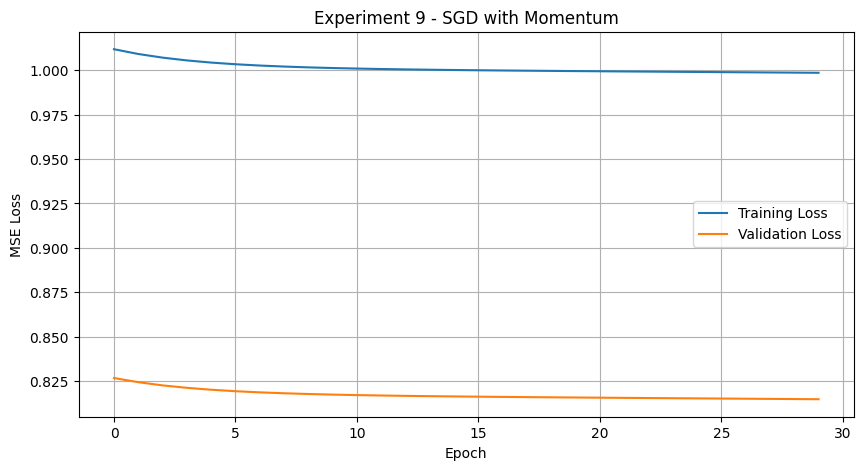

In [104]:
# EXPERIMENT 9 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp9_train_losses,
    label="Training Loss"
)

plt.plot(
    exp9_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 9 - SGD with Momentum")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [115]:
# EXPERIMENT 10 - SETUP BATCH SIZE 16

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp10_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 16
exp10_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define loss function
exp10_criterion = nn.MSELoss()

# Define Adam optimizer
exp10_optimizer = optim.Adam(
    exp10_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp10_train_losses = []
exp10_val_losses = []

# Number of epochs
exp10_epochs = 30

print("Experiment 10 setup completed!")

Experiment 10 setup completed!


In [116]:
# EXPERIMENT 10 - TRAIN MODEL (BATCH SIZE 16)

for epoch in range(exp10_epochs):

    # Set model to training mode
    exp10_model.train()

    total_train_loss = 0

    # Loop through training batches
    for X_batch, y_batch in exp10_train_loader:

        # Forward pass
        predictions = exp10_model(X_batch)

        # Calculate loss
        loss = exp10_criterion(predictions, y_batch)

        # Backpropagation
        exp10_optimizer.zero_grad()
        loss.backward()
        exp10_optimizer.step()

        # Accumulate training loss
        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp10_model.eval()

    with torch.no_grad():

        val_predictions = exp10_model(X_val_tensor)

        val_loss = exp10_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp10_train_losses.append(train_loss)
    exp10_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp10_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 10 completed!")

Epoch [1/30], Train Loss: 0.9384, Val Loss: 0.7152
Epoch [2/30], Train Loss: 0.8925, Val Loss: 0.7015
Epoch [3/30], Train Loss: 0.8818, Val Loss: 0.6945
Epoch [4/30], Train Loss: 0.8756, Val Loss: 0.6898
Epoch [5/30], Train Loss: 0.8716, Val Loss: 0.6870
Epoch [6/30], Train Loss: 0.8689, Val Loss: 0.6852
Epoch [7/30], Train Loss: 0.8669, Val Loss: 0.6842
Epoch [8/30], Train Loss: 0.8655, Val Loss: 0.6833
Epoch [9/30], Train Loss: 0.8646, Val Loss: 0.6828
Epoch [10/30], Train Loss: 0.8638, Val Loss: 0.6825
Epoch [11/30], Train Loss: 0.8632, Val Loss: 0.6822
Epoch [12/30], Train Loss: 0.8625, Val Loss: 0.6820
Epoch [13/30], Train Loss: 0.8620, Val Loss: 0.6819
Epoch [14/30], Train Loss: 0.8616, Val Loss: 0.6818
Epoch [15/30], Train Loss: 0.8611, Val Loss: 0.6818
Epoch [16/30], Train Loss: 0.8608, Val Loss: 0.6816
Epoch [17/30], Train Loss: 0.8603, Val Loss: 0.6815
Epoch [18/30], Train Loss: 0.8599, Val Loss: 0.6816
Epoch [19/30], Train Loss: 0.8594, Val Loss: 0.6816
Epoch [20/30], Train 

In [117]:
# EXPERIMENT 10 - EVALUATE MODEL

exp10_model.eval()

with torch.no_grad():

    exp10_val_scaled = exp10_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp10_val_predictions = target_scaler.inverse_transform(
        exp10_val_scaled
    )

    # Calculate validation MSE
    exp10_val_mse = mean_squared_error(
        y_val,
        exp10_val_predictions
    )

print("Experiment 10 Validation MSE:", exp10_val_mse)


Experiment 10 Validation MSE: 4508868608.0


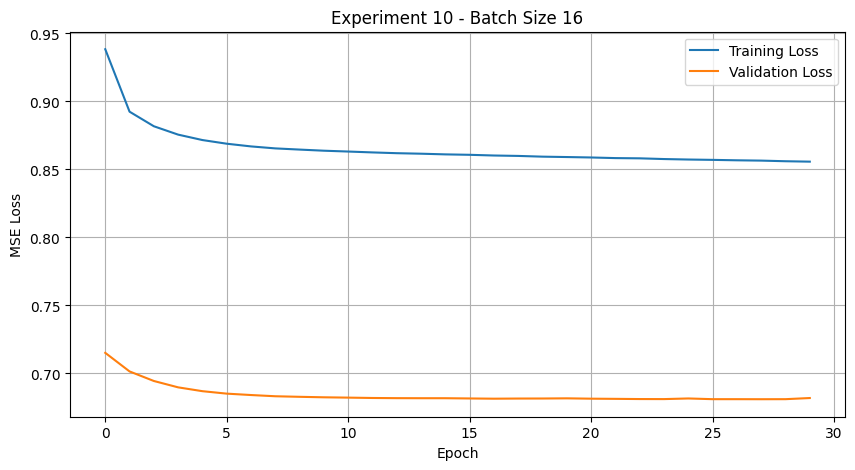

In [118]:
# EXPERIMENT 10 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp10_train_losses,
    label="Training Loss"
)

plt.plot(
    exp10_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 10 - Batch Size 16")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()


In [119]:
# EXPERIMENT 11 - SETUP BATCH SIZE 32

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp11_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 32
exp11_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# Define loss function
exp11_criterion = nn.MSELoss()

# Define Adam optimizer
exp11_optimizer = optim.Adam(
    exp11_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp11_train_losses = []
exp11_val_losses = []

# Number of epochs
exp11_epochs = 30

print("Experiment 11 setup completed!")

Experiment 11 setup completed!


In [120]:
# EXPERIMENT 11 - TRAIN MODEL

for epoch in range(exp11_epochs):

    exp11_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp11_train_loader:

        # Forward pass
        predictions = exp11_model(X_batch)

        # Calculate loss
        loss = exp11_criterion(predictions, y_batch)

        # Backpropagation
        exp11_optimizer.zero_grad()
        loss.backward()
        exp11_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp11_model.eval()

    with torch.no_grad():

        val_predictions = exp11_model(X_val_tensor)

        val_loss = exp11_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp11_train_losses.append(train_loss)
    exp11_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp11_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 11 completed!")

Epoch [1/30], Train Loss: 0.9559, Val Loss: 0.7242
Epoch [2/30], Train Loss: 0.9005, Val Loss: 0.7087
Epoch [3/30], Train Loss: 0.8890, Val Loss: 0.7008
Epoch [4/30], Train Loss: 0.8820, Val Loss: 0.6955
Epoch [5/30], Train Loss: 0.8772, Val Loss: 0.6920
Epoch [6/30], Train Loss: 0.8739, Val Loss: 0.6895
Epoch [7/30], Train Loss: 0.8712, Val Loss: 0.6877
Epoch [8/30], Train Loss: 0.8691, Val Loss: 0.6862
Epoch [9/30], Train Loss: 0.8677, Val Loss: 0.6853
Epoch [10/30], Train Loss: 0.8665, Val Loss: 0.6844
Epoch [11/30], Train Loss: 0.8655, Val Loss: 0.6840
Epoch [12/30], Train Loss: 0.8646, Val Loss: 0.6834
Epoch [13/30], Train Loss: 0.8639, Val Loss: 0.6831
Epoch [14/30], Train Loss: 0.8633, Val Loss: 0.6828
Epoch [15/30], Train Loss: 0.8628, Val Loss: 0.6827
Epoch [16/30], Train Loss: 0.8623, Val Loss: 0.6825
Epoch [17/30], Train Loss: 0.8618, Val Loss: 0.6823
Epoch [18/30], Train Loss: 0.8614, Val Loss: 0.6823
Epoch [19/30], Train Loss: 0.8609, Val Loss: 0.6823
Epoch [20/30], Train 

In [121]:
# EXPERIMENT 11 - EVALUATE MODEL

exp11_model.eval()

with torch.no_grad():

    exp11_val_scaled = exp11_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp11_val_predictions = target_scaler.inverse_transform(
        exp11_val_scaled
    )

    # Calculate validation MSE
    exp11_val_mse = mean_squared_error(
        y_val,
        exp11_val_predictions
    )

print("Experiment 11 Validation MSE:", exp11_val_mse)

Experiment 11 Validation MSE: 4511033856.0


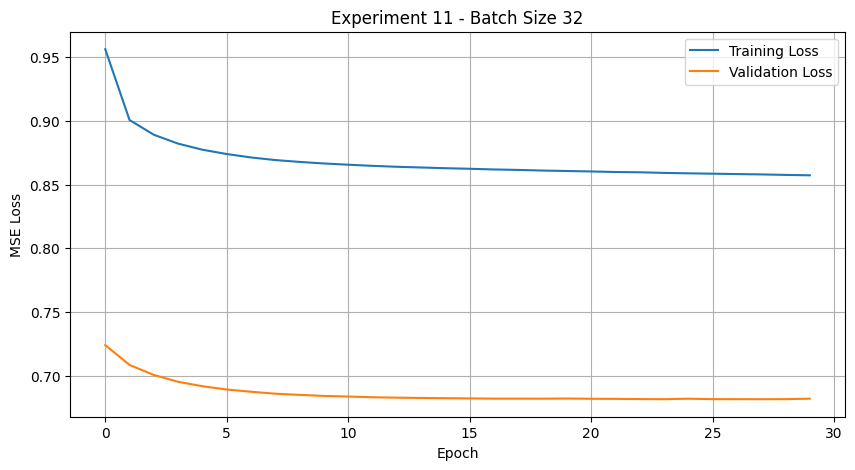

In [122]:
# EXPERIMENT 11 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp11_train_losses,
    label="Training Loss"
)

plt.plot(
    exp11_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 11 - Batch Size 32")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [123]:
# EXPERIMENT 12 - SETUP BATCH SIZE 64

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp12_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 64
exp12_train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Define loss function
exp12_criterion = nn.MSELoss()

# Define Adam optimizer
exp12_optimizer = optim.Adam(
    exp12_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp12_train_losses = []
exp12_val_losses = []

# Number of epochs
exp12_epochs = 30

print("Experiment 12 setup completed!")

Experiment 12 setup completed!


In [124]:
# EXPERIMENT 12 - TRAIN MODEL

for epoch in range(exp12_epochs):

    exp12_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp12_train_loader:

        # Forward pass
        predictions = exp12_model(X_batch)

        # Calculate loss
        loss = exp12_criterion(predictions, y_batch)

        # Backpropagation
        exp12_optimizer.zero_grad()
        loss.backward()
        exp12_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp12_model.eval()

    with torch.no_grad():

        val_predictions = exp12_model(X_val_tensor)

        val_loss = exp12_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp12_train_losses.append(train_loss)
    exp12_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp12_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 12 completed!")

Epoch [1/30], Train Loss: 0.9782, Val Loss: 0.7505
Epoch [2/30], Train Loss: 0.9130, Val Loss: 0.7169
Epoch [3/30], Train Loss: 0.8970, Val Loss: 0.7080
Epoch [4/30], Train Loss: 0.8893, Val Loss: 0.7021
Epoch [5/30], Train Loss: 0.8839, Val Loss: 0.6980
Epoch [6/30], Train Loss: 0.8799, Val Loss: 0.6948
Epoch [7/30], Train Loss: 0.8768, Val Loss: 0.6925
Epoch [8/30], Train Loss: 0.8743, Val Loss: 0.6905
Epoch [9/30], Train Loss: 0.8723, Val Loss: 0.6891
Epoch [10/30], Train Loss: 0.8706, Val Loss: 0.6879
Epoch [11/30], Train Loss: 0.8693, Val Loss: 0.6870
Epoch [12/30], Train Loss: 0.8681, Val Loss: 0.6861
Epoch [13/30], Train Loss: 0.8671, Val Loss: 0.6855
Epoch [14/30], Train Loss: 0.8663, Val Loss: 0.6849
Epoch [15/30], Train Loss: 0.8656, Val Loss: 0.6846
Epoch [16/30], Train Loss: 0.8649, Val Loss: 0.6842
Epoch [17/30], Train Loss: 0.8643, Val Loss: 0.6838
Epoch [18/30], Train Loss: 0.8638, Val Loss: 0.6836
Epoch [19/30], Train Loss: 0.8633, Val Loss: 0.6834
Epoch [20/30], Train 

In [125]:
# EXPERIMENT 12 - EVALUATE MODEL

exp12_model.eval()

with torch.no_grad():

    exp12_val_scaled = exp12_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp12_val_predictions = target_scaler.inverse_transform(
        exp12_val_scaled
    )

    # Calculate validation MSE
    exp12_val_mse = mean_squared_error(
        y_val,
        exp12_val_predictions
    )

print("Experiment 12 Validation MSE:", exp12_val_mse)

Experiment 12 Validation MSE: 4514146816.0


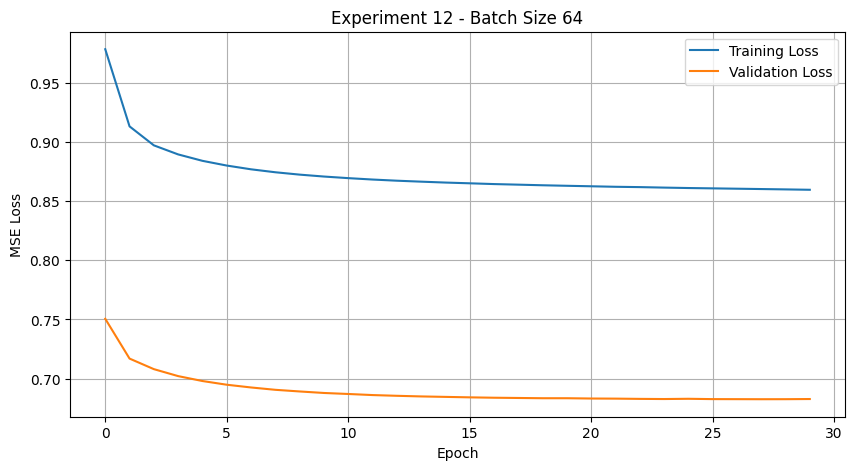

In [126]:
# EXPERIMENT 12 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp12_train_losses,
    label="Training Loss"
)

plt.plot(
    exp12_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 12 - Batch Size 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [127]:
# EXPERIMENT 13 - SETUP BATCH SIZE 128

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp13_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 128
exp13_train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

# Define loss function
exp13_criterion = nn.MSELoss()

# Define Adam optimizer
exp13_optimizer = optim.Adam(
    exp13_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp13_train_losses = []
exp13_val_losses = []

# Number of epochs
exp13_epochs = 30

print("Experiment 13 setup completed!")

Experiment 13 setup completed!


In [128]:
# EXPERIMENT 13 - TRAIN MODEL

for epoch in range(exp13_epochs):

    exp13_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp13_train_loader:

        # Forward pass
        predictions = exp13_model(X_batch)

        # Calculate loss
        loss = exp13_criterion(predictions, y_batch)

        # Backpropagation
        exp13_optimizer.zero_grad()
        loss.backward()
        exp13_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp13_model.eval()

    with torch.no_grad():

        val_predictions = exp13_model(X_val_tensor)

        val_loss = exp13_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp13_train_losses.append(train_loss)
    exp13_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp13_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 13 completed!")

Epoch [1/30], Train Loss: 0.9929, Val Loss: 0.7926
Epoch [2/30], Train Loss: 0.9458, Val Loss: 0.7333
Epoch [3/30], Train Loss: 0.9083, Val Loss: 0.7167
Epoch [4/30], Train Loss: 0.8980, Val Loss: 0.7097
Epoch [5/30], Train Loss: 0.8918, Val Loss: 0.7049
Epoch [6/30], Train Loss: 0.8872, Val Loss: 0.7012
Epoch [7/30], Train Loss: 0.8835, Val Loss: 0.6983
Epoch [8/30], Train Loss: 0.8806, Val Loss: 0.6959
Epoch [9/30], Train Loss: 0.8781, Val Loss: 0.6941
Epoch [10/30], Train Loss: 0.8761, Val Loss: 0.6924
Epoch [11/30], Train Loss: 0.8744, Val Loss: 0.6911
Epoch [12/30], Train Loss: 0.8728, Val Loss: 0.6899
Epoch [13/30], Train Loss: 0.8715, Val Loss: 0.6890
Epoch [14/30], Train Loss: 0.8704, Val Loss: 0.6881
Epoch [15/30], Train Loss: 0.8694, Val Loss: 0.6874
Epoch [16/30], Train Loss: 0.8685, Val Loss: 0.6868
Epoch [17/30], Train Loss: 0.8677, Val Loss: 0.6863
Epoch [18/30], Train Loss: 0.8670, Val Loss: 0.6858
Epoch [19/30], Train Loss: 0.8664, Val Loss: 0.6854
Epoch [20/30], Train 

In [129]:
# EXPERIMENT 13 - EVALUATE MODEL

exp13_model.eval()

with torch.no_grad():

    exp13_val_scaled = exp13_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp13_val_predictions = target_scaler.inverse_transform(
        exp13_val_scaled
    )

    # Calculate validation MSE
    exp13_val_mse = mean_squared_error(
        y_val,
        exp13_val_predictions
    )

print("Experiment 13 Validation MSE:", exp13_val_mse)

Experiment 13 Validation MSE: 4518858240.0


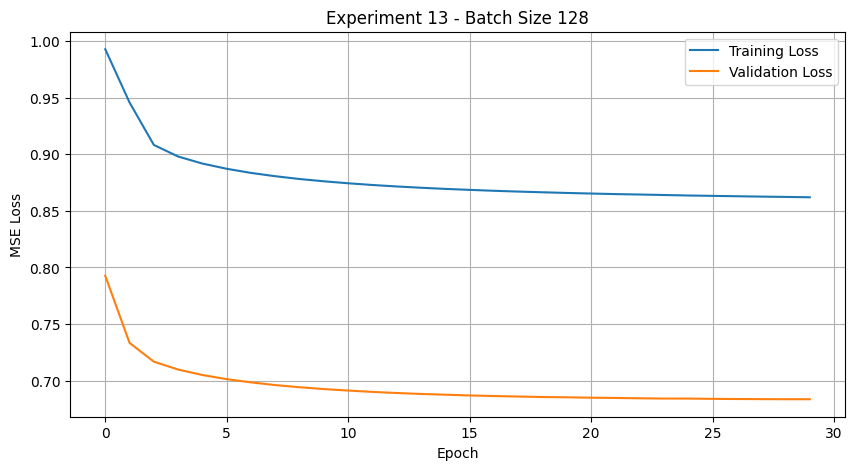

In [130]:
# EXPERIMENT 13 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp13_train_losses,
    label="Training Loss"
)

plt.plot(
    exp13_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 13 - Batch Size 128")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [131]:
# EXPERIMENT 14 - SETUP BATCH SIZE 256

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp14_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 256
exp14_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
exp14_criterion = nn.MSELoss()

# Define Adam optimizer
exp14_optimizer = optim.Adam(
    exp14_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp14_train_losses = []
exp14_val_losses = []

# Number of epochs
exp14_epochs = 30

print("Experiment 14 setup completed!")

Experiment 14 setup completed!


In [132]:
# EXPERIMENT 14 - TRAIN MODEL

for epoch in range(exp14_epochs):

    exp14_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp14_train_loader:

        # Forward pass
        predictions = exp14_model(X_batch)

        # Calculate loss
        loss = exp14_criterion(predictions, y_batch)

        # Backpropagation
        exp14_optimizer.zero_grad()
        loss.backward()
        exp14_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp14_model.eval()

    with torch.no_grad():

        val_predictions = exp14_model(X_val_tensor)

        val_loss = exp14_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp14_train_losses.append(train_loss)
    exp14_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp14_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 14 completed!")

Epoch [1/30], Train Loss: 0.9980, Val Loss: 0.8093
Epoch [2/30], Train Loss: 0.9822, Val Loss: 0.7832
Epoch [3/30], Train Loss: 0.9472, Val Loss: 0.7427
Epoch [4/30], Train Loss: 0.9157, Val Loss: 0.7224
Epoch [5/30], Train Loss: 0.9036, Val Loss: 0.7150
Epoch [6/30], Train Loss: 0.8975, Val Loss: 0.7102
Epoch [7/30], Train Loss: 0.8929, Val Loss: 0.7065
Epoch [8/30], Train Loss: 0.8892, Val Loss: 0.7034
Epoch [9/30], Train Loss: 0.8861, Val Loss: 0.7009
Epoch [10/30], Train Loss: 0.8836, Val Loss: 0.6989
Epoch [11/30], Train Loss: 0.8814, Val Loss: 0.6971
Epoch [12/30], Train Loss: 0.8795, Val Loss: 0.6956
Epoch [13/30], Train Loss: 0.8778, Val Loss: 0.6942
Epoch [14/30], Train Loss: 0.8763, Val Loss: 0.6930
Epoch [15/30], Train Loss: 0.8750, Val Loss: 0.6921
Epoch [16/30], Train Loss: 0.8739, Val Loss: 0.6911
Epoch [17/30], Train Loss: 0.8728, Val Loss: 0.6903
Epoch [18/30], Train Loss: 0.8719, Val Loss: 0.6896
Epoch [19/30], Train Loss: 0.8710, Val Loss: 0.6889
Epoch [20/30], Train 

In [133]:
# EXPERIMENT 14 - EVALUATE MODEL

exp14_model.eval()

with torch.no_grad():

    exp14_val_scaled = exp14_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp14_val_predictions = target_scaler.inverse_transform(
        exp14_val_scaled
    )

    # Calculate validation MSE
    exp14_val_mse = mean_squared_error(
        y_val,
        exp14_val_predictions
    )

print("Experiment 14 Validation MSE:", exp14_val_mse)

Experiment 14 Validation MSE: 4528403968.0


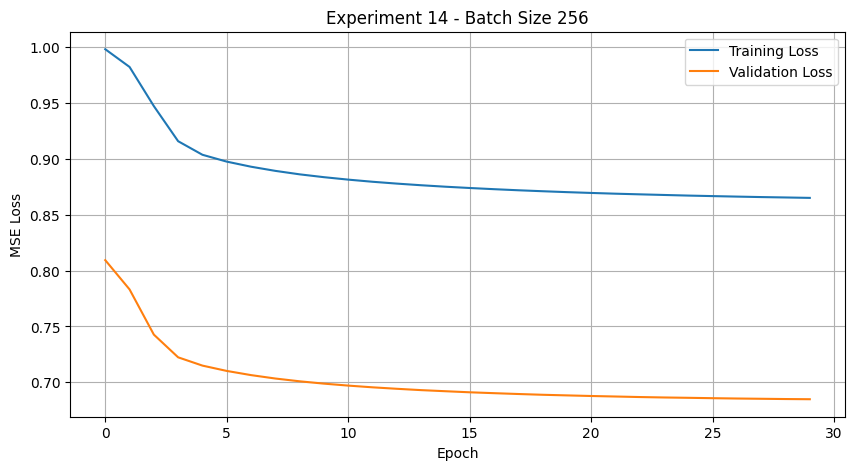

In [134]:
# EXPERIMENT 14 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp14_train_losses,
    label="Training Loss"
)

plt.plot(
    exp14_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 14 - Batch Size 256")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [135]:
# EXPERIMENT 15 - SETUP BATCH SIZE 512

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp15_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 512
exp15_train_loader = DataLoader(
    train_dataset,
    batch_size=512,
    shuffle=True
)

# Define loss function
exp15_criterion = nn.MSELoss()

# Define Adam optimizer
exp15_optimizer = optim.Adam(
    exp15_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp15_train_losses = []
exp15_val_losses = []

# Number of epochs
exp15_epochs = 30

print("Experiment 15 setup completed!")

Experiment 15 setup completed!


In [136]:
# EXPERIMENT 15 - TRAIN MODEL

for epoch in range(exp15_epochs):

    exp15_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp15_train_loader:

        # Forward pass
        predictions = exp15_model(X_batch)

        # Calculate loss
        loss = exp15_criterion(predictions, y_batch)

        # Backpropagation
        exp15_optimizer.zero_grad()
        loss.backward()
        exp15_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp15_model.eval()

    with torch.no_grad():

        val_predictions = exp15_model(X_val_tensor)

        val_loss = exp15_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp15_train_losses.append(train_loss)
    exp15_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp15_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 15 completed!")

Epoch [1/30], Train Loss: 1.0000, Val Loss: 0.8143
Epoch [2/30], Train Loss: 0.9949, Val Loss: 0.8074
Epoch [3/30], Train Loss: 0.9851, Val Loss: 0.7939
Epoch [4/30], Train Loss: 0.9679, Val Loss: 0.7725
Epoch [5/30], Train Loss: 0.9447, Val Loss: 0.7480
Epoch [6/30], Train Loss: 0.9232, Val Loss: 0.7299
Epoch [7/30], Train Loss: 0.9102, Val Loss: 0.7209
Epoch [8/30], Train Loss: 0.9035, Val Loss: 0.7160
Epoch [9/30], Train Loss: 0.8991, Val Loss: 0.7123
Epoch [10/30], Train Loss: 0.8956, Val Loss: 0.7093
Epoch [11/30], Train Loss: 0.8925, Val Loss: 0.7067
Epoch [12/30], Train Loss: 0.8898, Val Loss: 0.7044
Epoch [13/30], Train Loss: 0.8874, Val Loss: 0.7025
Epoch [14/30], Train Loss: 0.8854, Val Loss: 0.7007
Epoch [15/30], Train Loss: 0.8835, Val Loss: 0.6992
Epoch [16/30], Train Loss: 0.8819, Val Loss: 0.6979
Epoch [17/30], Train Loss: 0.8805, Val Loss: 0.6967
Epoch [18/30], Train Loss: 0.8792, Val Loss: 0.6956
Epoch [19/30], Train Loss: 0.8780, Val Loss: 0.6946
Epoch [20/30], Train 

In [137]:
# EXPERIMENT 15 - EVALUATE MODEL

exp15_model.eval()

with torch.no_grad():

    exp15_val_scaled = exp15_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp15_val_predictions = target_scaler.inverse_transform(
        exp15_val_scaled
    )

    # Calculate validation MSE
    exp15_val_mse = mean_squared_error(
        y_val,
        exp15_val_predictions
    )

print("Experiment 15 Validation MSE:", exp15_val_mse)

Experiment 15 Validation MSE: 4548371456.0


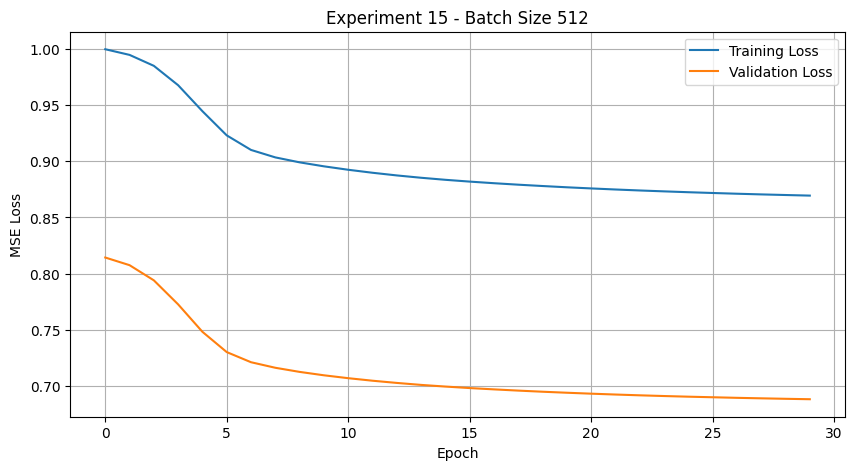

In [138]:
# EXPERIMENT 15 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp15_train_losses,
    label="Training Loss"
)

plt.plot(
    exp15_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 15 - Batch Size 512")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [139]:
# EXPERIMENT 16 - SETUP BATCH SIZE 8

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp16_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 8
exp16_train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

# Define loss function
exp16_criterion = nn.MSELoss()

# Define Adam optimizer
exp16_optimizer = optim.Adam(
    exp16_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp16_train_losses = []
exp16_val_losses = []

# Number of epochs
exp16_epochs = 30

print("Experiment 16 setup completed!")

Experiment 16 setup completed!


In [140]:
# EXPERIMENT 16 - TRAIN MODEL

for epoch in range(exp16_epochs):

    exp16_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp16_train_loader:

        predictions = exp16_model(X_batch)

        loss = exp16_criterion(predictions, y_batch)

        exp16_optimizer.zero_grad()
        loss.backward()
        exp16_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    # Validate model
    exp16_model.eval()

    with torch.no_grad():

        val_predictions = exp16_model(X_val_tensor)

        val_loss = exp16_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    exp16_train_losses.append(train_loss)
    exp16_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 16 completed!")

Epoch [1/30], Train Loss: 0.9249, Val Loss: 0.7077
Epoch [2/30], Train Loss: 0.8851, Val Loss: 0.6947
Epoch [3/30], Train Loss: 0.8755, Val Loss: 0.6889
Epoch [4/30], Train Loss: 0.8706, Val Loss: 0.6853
Epoch [5/30], Train Loss: 0.8678, Val Loss: 0.6837
Epoch [6/30], Train Loss: 0.8660, Val Loss: 0.6828
Epoch [7/30], Train Loss: 0.8647, Val Loss: 0.6826
Epoch [8/30], Train Loss: 0.8638, Val Loss: 0.6822
Epoch [9/30], Train Loss: 0.8633, Val Loss: 0.6819
Epoch [10/30], Train Loss: 0.8626, Val Loss: 0.6817
Epoch [11/30], Train Loss: 0.8622, Val Loss: 0.6814
Epoch [12/30], Train Loss: 0.8616, Val Loss: 0.6812
Epoch [13/30], Train Loss: 0.8610, Val Loss: 0.6810
Epoch [14/30], Train Loss: 0.8607, Val Loss: 0.6811
Epoch [15/30], Train Loss: 0.8602, Val Loss: 0.6811
Epoch [16/30], Train Loss: 0.8599, Val Loss: 0.6809
Epoch [17/30], Train Loss: 0.8594, Val Loss: 0.6809
Epoch [18/30], Train Loss: 0.8591, Val Loss: 0.6811
Epoch [19/30], Train Loss: 0.8585, Val Loss: 0.6813
Epoch [20/30], Train 

In [142]:
# EXPERIMENT 16 - EVALUATE MODEL

exp16_model.eval()

with torch.no_grad():

    exp16_val_scaled = exp16_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp16_val_predictions = target_scaler.inverse_transform(
        exp16_val_scaled
    )

    # Calculate validation MSE
    exp16_val_mse = mean_squared_error(
        y_val,
        exp16_val_predictions
    )

print("Experiment 16 Validation MSE:", exp16_val_mse)

Experiment 16 Validation MSE: 4510700032.0


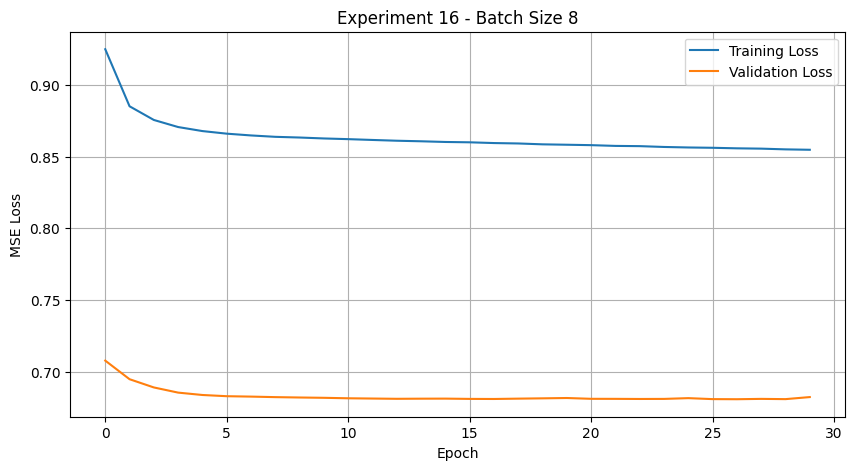

In [143]:
# EXPERIMENT 16 - PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    exp16_train_losses,
    label="Training Loss"
)

plt.plot(
    exp16_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 16 - Batch Size 8")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()